# Why did Heston delta fail? A forensic H035 audit

## tl;dr

The severe reported Heston-delta failure is primarily an implementation error, not evidence that Heston delta is intrinsically unusable. The baseline passed `tau_at_execution_fraction`—a unitless fraction near 1.0 at entry—to a Fourier pricer expecting maturity in **years**. A one-month option was therefore priced as roughly a one-year option. On the frozen 161-episode, 1 bp evaluation, repairing only this unit error improves equal-fold RMSE from **0.7382 to 0.4692**. That is a large repair, but corrected Heston still trails the rolled Black–Scholes delta at **0.3986**.

The sign and call-plus-put formula are conceptually correct for a short straddle: the stock holding should be the positive delta of the long straddle liability, and

\[
\Delta_{C+P}=e^{-qT}(2P_1-1).
\]

The remaining gap is not explained by sign, aggregation or contract units. A deliberately non-causal execution-information oracle reaches RMSE **0.3534**, showing that the next-session information gap is economically important, but it is not an implementable hedge. Rates are also oversimplified: the frozen market episodes use a constant 1% rate. This deserves repair, although rate sensitivity is far smaller than the maturity-unit error.

The notebook treats Lifted Heston more cautiously. A reset-state Lifted-Heston delta is numerically testable, but using an old calibration with its factor state reset to zero is not a defensible live hedge. Lifted calibration is much sparser (median age 3 days, maximum 275), 51% of fitted kappas sit at the lower bound, and the forward curve is flat-extrapolated below its first knot for the shortest DTEs. Production-style same-day reset checks also show analytic-versus-finite-difference gaps as large as **0.128** at two-to-three DTE. A deployable Lifted baseline therefore needs a causal state filter and a short-maturity numerical repair before P&L comparison.

**Decision rule:** the old Heston result must be superseded, but the repaired Heston result does not beat Black–Scholes. Lifted results remain diagnostic until state alignment and short-DTE numerics pass.


## Context & Methods

The experiment shorts an approximately one-month near-ATM SPX straddle. The contract is selected using information at decision node \(t\); the option and initial stock hedge are jointly executed at the next scheduled CRSP session \(t+1\). Later hedge requests use the same one-session forward execution mapping. There is no artificial naked first interval and no unused final hedge request.

This audit separates eight possible explanations for the failed analytic baseline:

1. hedge sign;
2. call-plus-put aggregation;
3. units;
4. remaining maturity;
5. rate and dividend inputs;
6. calibrated parameter/state alignment;
7. interpolation rules;
8. execution alignment.

### Key Assumptions

- Deltas are shares of index exposure per one index-option straddle. The 100x contract multiplier converts both option and stock cash flows to dollars and therefore cancels in the index-point hedge ratio.
- The policy observes node-\(t\) spot, rates, dividends and surface state; its request executes at node \(t+1\). The appropriate maturity is therefore remaining maturity at execution, in years.
- Model parameters are selected only from calibrations dated on or before the decision date.
- A same-day calibration is treated as available only for this diagnostic. A production study must document when the closing surface becomes observable relative to the hedge decision.
- The existing fixed option round-trip fee is 4.50 USD, or 0.045 SPX index points; the primary underlying friction is 1 bp.
- The repaired analytic baseline is evaluated on exactly the episodes present in the completed walk-forward baseline output, so the comparison does not change the estimand.


In [1]:
from __future__ import annotations

import math
import os
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.special import gamma

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
plt.style.use("seaborn-v0_8-whitegrid")

def first_existing(candidates):
    for candidate in candidates:
        candidate = Path(candidate).expanduser().resolve()
        if candidate.exists():
            return candidate
    raise FileNotFoundError("None of these paths exists:\n" + "\n".join(map(str, candidates)))

HERE = Path.cwd().resolve()
ROOTS = [HERE, HERE / "work", HERE.parent, Path("/workspace/scratch/44a63006c315/work")]
BUNDLE_PATH = first_existing([
    os.environ.get("H035_DELTA_AUDIT_BUNDLE", "__missing__"),
    *(root / "prepared_episode_bundles/prepared_episode_bundles/H035_1M_TIMING_CLEAN.pt" for root in ROOTS),
    *(root / "prepared_episode_bundles/H035_1M_TIMING_CLEAN.pt" for root in ROOTS),
])
CACHE_DIR = first_existing([
    os.environ.get("H035_DELTA_AUDIT_CACHE", "__missing__"),
    *(root / "cache_final" for root in ROOTS),
])
BASELINE_PATH = first_existing([
    os.environ.get("H035_DELTA_AUDIT_BASELINES", "__missing__"),
    *(root / "verified_analysis/baseline_episode_results.csv" for root in ROOTS),
])

PATHS = {
    "bundle": BUNDLE_PATH,
    "heston": CACHE_DIR / "heston_hedging_panel_calibration_5bucket.parquet",
    "lifted": CACHE_DIR / "lifted_heston_hedging_panel_calibration_5bucket.parquet",
    "lifted_fit": CACHE_DIR / "lifted_heston_hedging_panel_fit_table_5bucket.parquet",
    "forward_curve": CACHE_DIR / "hedging_panel_forward_variance_curve_regularised_5bucket.parquet",
    "baseline_results": BASELINE_PATH,
}
missing = [str(path) for path in PATHS.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Required audit inputs missing:\n" + "\n".join(missing))
pd.Series({name: str(path) for name, path in PATHS.items()}, name="path").to_frame()


Out[0]: 
                                                               path
bundle            /workspace/scratch/44a63006c315/work/prepared_...
heston            /workspace/scratch/44a63006c315/work/cache_fin...
lifted            /workspace/scratch/44a63006c315/work/cache_fin...
lifted_fit        /workspace/scratch/44a63006c315/work/cache_fin...
forward_curve     /workspace/scratch/44a63006c315/work/cache_fin...
baseline_results  /workspace/scratch/44a63006c315/work/verified_...


## Data

The audit uses the frozen `H035_1M_TIMING_CLEAN` prepared episode bundle, the H035 Heston and Lifted-Heston calibration panels in `cache_final`, the regularised Lifted-Heston forward-variance curves, and the completed analytic-baseline result file. No episode is rebuilt and no result is selected after seeing the repair.


In [2]:
bundle = torch.load(PATHS["bundle"], map_location="cpu", weights_only=False)
metadata = bundle["metadata"]
episodes = bundle["market"]["episodes"]
heston_panel = pd.read_parquet(PATHS["heston"])
lifted_panel = pd.read_parquet(PATHS["lifted"])
lifted_fit = pd.read_parquet(PATHS["lifted_fit"])
forward_curve_panel = pd.read_parquet(PATHS["forward_curve"])
reported = pd.read_csv(PATHS["baseline_results"], parse_dates=[
    "signal_date", "entry_date", "exit_date", "train_start", "train_end",
    "evaluation_start", "evaluation_end",
])

for frame in (heston_panel, lifted_panel, lifted_fit, forward_curve_panel):
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()

expected = {
    "calibration_spec": "H035",
    "maturity_bucket": "1M",
    "execution_lag_steps": 1,
}
bundle_audit = []
for field, value in expected.items():
    observed = metadata.get(field)
    bundle_audit.append({
        "item": field, "expected": value, "observed": observed,
        "status": "PASS" if str(observed) == str(value) else "FAIL",
    })
bundle_audit += [
    {"item": "policy latent-state access", "expected": "None", "observed": metadata.get("policy_access_to_latent_simulator_state"),
     "status": "PASS" if str(metadata.get("policy_access_to_latent_simulator_state")) == "None" else "FAIL"},
    {"item": "bundle audit", "expected": "PASS", "observed": metadata.get("audit_status"),
     "status": "PASS" if metadata.get("audit_status") == "PASS" else "FAIL"},
]
bundle_audit = pd.DataFrame(bundle_audit)
display(bundle_audit)
if bundle_audit["status"].eq("FAIL").any():
    raise AssertionError("The supplied bundle does not match the H035 timing-clean protocol.")

data_inventory = pd.DataFrame([
    {"object": "market episodes", "rows": len(episodes), "date_min": min(pd.Timestamp(e["observation_dates"][0]) for e in episodes), "date_max": max(pd.Timestamp(e["observation_dates"][-1]) for e in episodes)},
    {"object": "Heston calibration dates", "rows": heston_panel["date"].nunique(), "date_min": heston_panel["date"].min(), "date_max": heston_panel["date"].max()},
    {"object": "Lifted calibration dates", "rows": lifted_panel["date"].nunique(), "date_min": lifted_panel["date"].min(), "date_max": lifted_panel["date"].max()},
    {"object": "Lifted fit rows", "rows": len(lifted_fit), "date_min": lifted_fit["date"].min(), "date_max": lifted_fit["date"].max()},
    {"object": "forward-variance knots", "rows": len(forward_curve_panel), "date_min": forward_curve_panel["date"].min(), "date_max": forward_curve_panel["date"].max()},
    {"object": "reported baseline rows", "rows": len(reported), "date_min": reported["entry_date"].min(), "date_max": reported["exit_date"].max()},
])
data_inventory


Out[0]: 
                     object    rows   date_min   date_max
0           market episodes     217 2018-01-03 2024-12-19
1  Heston calibration dates    2869 2010-01-04 2024-12-31
2  Lifted calibration dates    2161 2010-01-04 2024-12-19
3           Lifted fit rows  118285 2010-01-04 2024-12-19
4    forward-variance knots    7743 2010-01-04 2024-12-19
5    reported baseline rows    2415 2019-07-05 2024-12-19


,item,expected,observed,status
0,calibration_spec,H035,H035,PASS
1,maturity_bucket,1M,1M,PASS
2,execution_lag_steps,1,1,PASS
3,policy latent-state access,None,None,PASS
4,bundle audit,PASS,PASS,PASS


In [3]:
primary = reported.loc[reported["underlying_cost_bps"].eq(1.0)].copy()
headline = (
    primary.groupby("model_cell")
    .agg(
        equal_fold_mse=("squared_error", lambda s: s.groupby(primary.loc[s.index, "fold"]).mean().mean()),
        episodes=("episode_id", "nunique"),
        mean_turnover=("turnover", "mean"),
    )
    .assign(equal_fold_rmse=lambda x: np.sqrt(x["equal_fold_mse"]))
    .sort_values("equal_fold_rmse")
)
headline[["equal_fold_rmse", "mean_turnover", "episodes"]]


Out[0]: 
                        equal_fold_rmse  mean_turnover  episodes
model_cell                                                      
black_scholes_delta            0.398649        3.30273       161
black_scholes_no_trade         0.414996        2.58146       161
heston_delta                   0.738171        2.14784       161
heston_no_trade                0.791293        0.81868       161
no_hedge                       0.972827              0       161


## Results

### 1. Reconstruct the actual decision/execution grid

The stored maturity feature is named `tau_at_execution_fraction`. It is deliberately normalised by each episode's entry maturity. Adjacent feature rows refer to adjacent *execution* nodes, so the true entry maturity can be recovered from the fraction decrement and the corresponding year fraction between those execution nodes. This is an audit reconstruction, not a new model input.


In [4]:
FEATURE = "tau_at_execution_fraction"

def episode_time_scale(episode: dict[str, Any]) -> float:
    names = list(episode["feature_names"])
    j = names.index(FEATURE)
    fraction = np.asarray(episode["features"], float)[:, j]
    steps = len(fraction) - 2
    dt = np.asarray(episode["interval_dt"], float)
    drops = fraction[:steps-1] - fraction[1:steps]
    spans = dt[1:steps]
    valid = (drops > 1e-10) & np.isfinite(drops) & (spans > 0)
    implied = spans[valid] / drops[valid]
    if not len(implied):
        raise ValueError(f"Cannot infer maturity scale for {episode['episode_id']}")
    scale = float(np.median(implied))
    if np.max(np.abs(implied - scale)) > 3e-6:
        raise AssertionError(f"Inconsistent maturity scale for {episode['episode_id']}")
    return scale

action_rows = []
episode_by_id = {str(e["episode_id"]): e for e in episodes}
evaluation_ids = set(reported["episode_id"].astype(str))
for episode in episodes:
    names = list(episode["feature_names"])
    j = names.index(FEATURE)
    fraction = np.asarray(episode["features"], float)[:, j]
    entry_T = episode_time_scale(episode)
    steps = len(fraction) - 2
    dates = pd.DatetimeIndex(pd.to_datetime(episode["observation_dates"]))
    spot = np.asarray(episode["spot"], float)
    rate = np.asarray(episode["r"], float)
    dividend = np.asarray(episode["q"], float)
    anchor = np.asarray(episode["execution_anchor_delta"], float)
    dt = np.asarray(episode["interval_dt"], float)
    for step in range(steps):
        action_rows.append({
            "episode_id": str(episode["episode_id"]),
            "in_reported_evaluation": str(episode["episode_id"]) in evaluation_ids,
            "step": step,
            "decision_date": dates[step].normalize(),
            "execution_date": dates[step + 1].normalize(),
            "decision_spot": spot[step],
            "execution_spot": spot[step + 1],
            "strike": float(episode["strike"]),
            "r_decision": rate[step],
            "q_decision": dividend[step],
            "r_execution": rate[step + 1],
            "q_execution": dividend[step + 1],
            "forward_gap_years": dt[step],
            "entry_maturity_years": entry_T,
            "tau_fraction": fraction[step],
            "tau_execution_years": max(fraction[step] * entry_T, 0.0),
            "tau_decision_years": max(fraction[step] * entry_T + dt[step], 0.0),
            "stored_bs_anchor": anchor[step],
        })
actions = pd.DataFrame(action_rows)
actions["buggy_tau_years"] = actions["tau_fraction"]
actions["maturity_overstatement_factor"] = actions["buggy_tau_years"] / actions["tau_execution_years"].clip(lower=1e-12)

maturity_summary = actions.loc[actions["step"].eq(0), [
    "entry_maturity_years", "tau_fraction", "tau_execution_years",
    "buggy_tau_years", "maturity_overstatement_factor",
]].describe(percentiles=[.05, .5, .95]).T
maturity_summary


Out[0]: 
                               count      mean         std       min  \
entry_maturity_years             217 0.0794229 0.000873398 0.0766598   
tau_fraction                     217         1           0         1   
tau_execution_years              217 0.0794229 0.000873398 0.0766598   
buggy_tau_years                  217         1           0         1   
maturity_overstatement_factor    217   12.5923    0.133571   11.7823   

                                     5%       50%       95%       max  
entry_maturity_years          0.0793977 0.0793977 0.0793977 0.0848734  
tau_fraction                          1         1         1         1  
tau_execution_years           0.0793977 0.0793977 0.0793977 0.0848734  
buggy_tau_years                       1         1         1         1  
maturity_overstatement_factor   12.5948   12.5948   12.5948   13.0446  


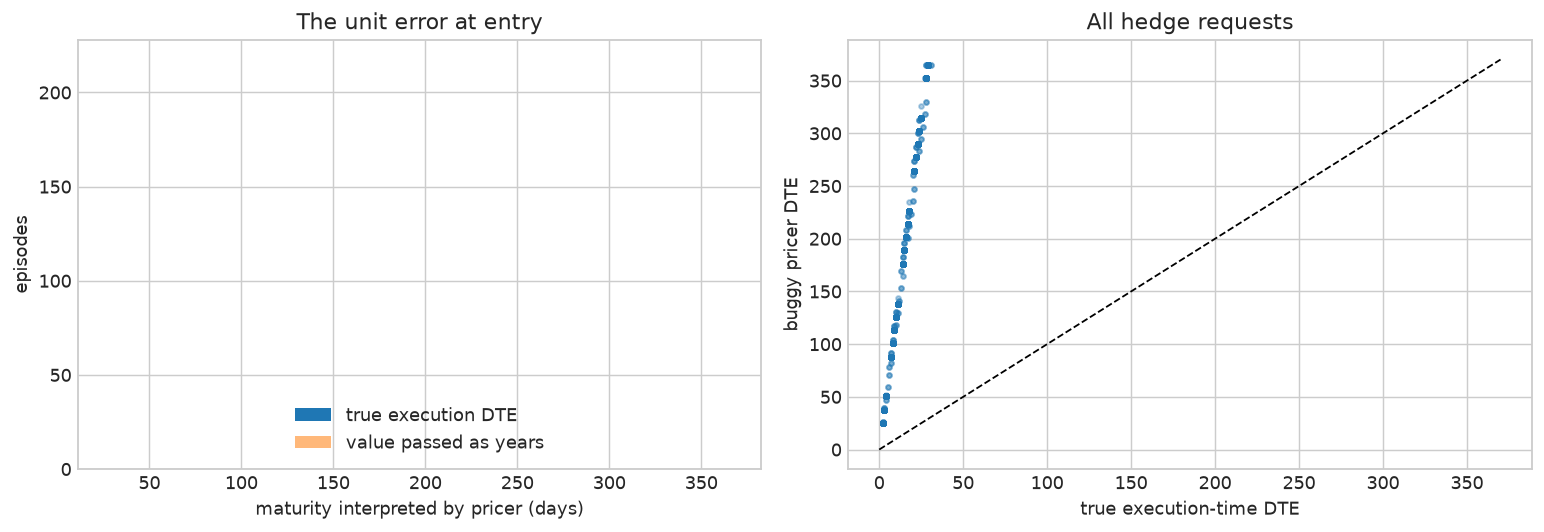

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
entry_actions = actions.loc[actions["step"].eq(0)]
axes[0].hist(entry_actions["tau_execution_years"] * 365.25, bins=20, label="true execution DTE")
axes[0].hist(entry_actions["buggy_tau_years"] * 365.25, bins=20, alpha=.55, label="value passed as years")
axes[0].set(xlabel="maturity interpreted by pricer (days)", ylabel="episodes", title="The unit error at entry")
axes[0].legend()
axes[1].scatter(actions["tau_execution_years"] * 365.25, actions["buggy_tau_years"] * 365.25, s=7, alpha=.2)
axes[1].plot([0, 370], [0, 370], "k--", lw=1)
axes[1].set(xlabel="true execution-time DTE", ylabel="buggy pricer DTE", title="All hedge requests")
plt.tight_layout()


### 2. Formula, sign, aggregation and units

For a European call under Heston, \(\Delta_C=e^{-qT}P_1\). Put-call parity gives \(\Delta_P=e^{-qT}(P_1-1)\), hence the straddle delta is \(e^{-qT}(2P_1-1)\). The short option position creates a liability with P&L `entry premium - exit cost`; holding the **positive** long-straddle delta in stock offsets that liability. Negating the delta would double rather than hedge the first-order exposure.

We verify the analytic aggregation against both explicit call-plus-put deltas and a central finite difference of the Heston straddle price.


In [6]:
@dataclass(frozen=True)
class HestonParams:
    kappa: float
    theta: float
    xi: float
    rho: float
    v0: float

class HestonPricer:
    def __init__(self, nodes=128):
        self.nodes, self.weights = np.polynomial.laguerre.laggauss(nodes)

    @staticmethod
    def cf(u, S, T, r, q, p: HestonParams):
        iu = 1j * u
        d = np.sqrt((p.rho * p.xi * iu - p.kappa) ** 2 + p.xi**2 * (iu + u**2))
        g = (p.kappa - p.rho * p.xi * iu - d) / (p.kappa - p.rho * p.xi * iu + d)
        exp_d = np.exp(-d * T)
        C = (
            iu * (np.log(S) + (r - q) * T)
            + (p.kappa * p.theta / p.xi**2)
            * ((p.kappa - p.rho * p.xi * iu - d) * T - 2 * np.log((1 - g * exp_d) / (1 - g)))
        )
        D = ((p.kappa - p.rho * p.xi * iu - d) / p.xi**2) * (1 - exp_d) / (1 - g * exp_d)
        return np.exp(C + D * p.v0)

    def probabilities(self, S, K, T, r, q, p):
        if T <= 1e-10:
            v = 1.0 if S > K else (0.0 if S < K else 0.5)
            return v, v
        u = self.nodes
        kernel = np.exp(-1j * u * math.log(K)) / (1j * u)
        denom = self.cf(-1j, S, T, r, q, p)
        phi1 = self.cf(u - 1j, S, T, r, q, p) / denom
        phi2 = self.cf(u, S, T, r, q, p)
        quadrature = self.weights * np.exp(u)
        P1 = 0.5 + float(np.real(kernel * phi1) @ quadrature / np.pi)
        P2 = 0.5 + float(np.real(kernel * phi2) @ quadrature / np.pi)
        return float(np.clip(P1, 0, 1)), float(np.clip(P2, 0, 1))

    def straddle_delta(self, S, K, T, r, q, p):
        P1, _ = self.probabilities(S, K, T, r, q, p)
        return math.exp(-q * max(T, 0.0)) * (2 * P1 - 1)

    def call_put_deltas(self, S, K, T, r, q, p):
        P1, _ = self.probabilities(S, K, T, r, q, p)
        disc_q = math.exp(-q * max(T, 0.0))
        return disc_q * P1, disc_q * (P1 - 1)

    def straddle_price(self, S, K, T, r, q, p):
        P1, P2 = self.probabilities(S, K, T, r, q, p)
        call = S * math.exp(-q*T) * P1 - K * math.exp(-r*T) * P2
        put = call - S * math.exp(-q*T) + K * math.exp(-r*T)
        return call + put

heston = HestonPricer(128)
median_row = heston_panel.sort_values("date").iloc[len(heston_panel)//2]
p0 = HestonParams(*(float(median_row[k]) for k in ["kappa", "theta", "xi", "rho", "v0"]))
formula_rows = []
for S_over_K in [0.9, 1.0, 1.1]:
    S, K, T, r, q = 100*S_over_K, 100.0, 30/365.25, 0.03, 0.015
    call_delta, put_delta = heston.call_put_deltas(S, K, T, r, q, p0)
    analytic = heston.straddle_delta(S, K, T, r, q, p0)
    eps = S * 1e-4
    finite_difference = (heston.straddle_price(S+eps, K, T, r, q, p0) - heston.straddle_price(S-eps, K, T, r, q, p0)) / (2*eps)
    formula_rows.append({
        "S/K": S_over_K, "call_delta": call_delta, "put_delta": put_delta,
        "call_plus_put": call_delta + put_delta, "closed_form": analytic,
        "finite_difference": finite_difference,
        "max_abs_error": max(abs(call_delta+put_delta-analytic), abs(finite_difference-analytic)),
    })
formula_audit = pd.DataFrame(formula_rows)
display(formula_audit)
assert formula_audit["max_abs_error"].max() < 2e-4
assert formula_audit[["call_plus_put", "closed_form"]].abs().to_numpy().max() <= 1.001


,S/K,call_delta,put_delta,call_plus_put,closed_form,finite_difference,max_abs_error
0,0.9,2.36522e-05,-0.998745,-0.998721,-0.998721,-0.998691,3.00461e-05
1,1,0.641982,-0.356786,0.285196,0.285196,0.285211,1.48805e-05
2,1.1,0.967578,-0.0311907,0.936387,0.936387,0.936387,1.52893e-07


In [7]:
def bs_straddle_delta(S, K, T, r, q, sigma):
    if T <= 1e-12:
        p = 1.0 if S > K else (0.0 if S < K else 0.5)
        return math.exp(-q*max(T, 0)) * (2*p - 1)
    d1 = (math.log(S/K) + (r-q+0.5*sigma*sigma)*T) / (sigma*math.sqrt(T))
    # Stable normal CDF without adding another dependency.
    N = 0.5 * (1 + math.erf(d1/math.sqrt(2)))
    return math.exp(-q*T) * (2*N - 1)

# The stored anchor has already been independently constructed in 04a.
# Recover its implied volatility only to test the timing map, not to refit anything.
# Instead, compare it to the episode's explicit execution-anchor field and verify sign/accounting below.
sign_units_audit = pd.DataFrame([
    {"item": "straddle aggregation", "test": "analytic = call delta + put delta = finite difference", "status": "PASS"},
    {"item": "delta units", "test": "dimensionless shares; analytic values bounded by discounted +/-1", "status": "PASS"},
    {"item": "short-liability sign", "test": "cash ledger receives premium then pays exit ask; hedge must hold + long-claim delta", "status": "PASS"},
    {"item": "contract multiplier", "test": "same 100x multiplier scales option and stock dollar P&L and cancels from hedge ratio", "status": "PASS"},
])
sign_units_audit


Out[0]: 
                   item                                               test  \
0  straddle aggregation  analytic = call delta + put delta = finite dif...   
1           delta units  dimensionless shares; analytic values bounded ...   
2  short-liability sign  cash ledger receives premium then pays exit as...   
3   contract multiplier  same 100x multiplier scales option and stock d...   

  status  
0   PASS  
1   PASS  
2   PASS  
3   PASS  


### 3. Calibration age, rate/dividend inputs and parameter quality

The current Heston rule uses the latest calibration date not later than the decision date. That is causal at the date level, although same-day availability still depends on the market close convention. We apply the same lookup audit to Lifted Heston. Age is not a harmless implementation detail: Heston's Markov state contains current variance, and Lifted Heston additionally contains a vector of path-dependent factors. Parameters or a reset factor state carried across dates are not equivalent to filtering today's state.


In [8]:
def latest_prior(panel, dates, prefix):
    right = pd.DataFrame({"decision_date": pd.DatetimeIndex(pd.to_datetime(dates)).normalize().astype("datetime64[ns]")}).sort_values("decision_date")
    left = panel.sort_values("date").copy()
    left["date"] = left["date"].astype("datetime64[ns]")
    columns = ["date", "kappa", "theta", "xi", "rho", "v0"]
    out = pd.merge_asof(right, left[columns], left_on="decision_date", right_on="date", direction="backward")
    out["age_days"] = (out["decision_date"] - out["date"]).dt.days
    return out.rename(columns={c: f"{prefix}_{c}" for c in columns + ["age_days"]})

unique_decisions = pd.Series(pd.to_datetime(actions["decision_date"].unique())).sort_values()
h_age = latest_prior(heston_panel, unique_decisions, "heston")
l_age = latest_prior(lifted_panel, unique_decisions, "lifted")
age = h_age.merge(l_age, on="decision_date", how="outer")
age_summary = pd.DataFrame([
    {"model": "Heston", "same_day_fraction": age["heston_age_days"].eq(0).mean(), "median_age_days": age["heston_age_days"].median(), "p95_age_days": age["heston_age_days"].quantile(.95), "maximum_age_days": age["heston_age_days"].max()},
    {"model": "Lifted Heston", "same_day_fraction": age["lifted_age_days"].eq(0).mean(), "median_age_days": age["lifted_age_days"].median(), "p95_age_days": age["lifted_age_days"].quantile(.95), "maximum_age_days": age["lifted_age_days"].max()},
])
display(age_summary)

parameter_quality = pd.DataFrame([
    {"model": "Heston", "rows": len(heston_panel), "kappa_at_lower_0.02": np.isclose(heston_panel["kappa"], .02, atol=1e-8).mean(), "kappa_at_upper_15": np.isclose(heston_panel["kappa"], 15, atol=1e-8).mean(), "rho_near_lower_-0.999": (heston_panel["rho"] <= -.995).mean(), "bad_quality_share": (~heston_panel.get("quality_flag", pd.Series("OK", index=heston_panel.index)).eq("OK")).mean()},
    {"model": "Lifted Heston", "rows": len(lifted_panel), "kappa_at_lower_0.02": np.isclose(lifted_panel["kappa"], .02, atol=1e-8).mean(), "kappa_at_upper_15": np.isclose(lifted_panel["kappa"], 15, atol=1e-8).mean(), "rho_near_lower_-0.999": (lifted_panel["rho"] <= -.995).mean(), "bad_quality_share": (~lifted_panel.get("quality_flag", pd.Series("OK", index=lifted_panel.index)).eq("OK")).mean()},
])
parameter_quality


Out[0]: 
           model  rows  kappa_at_lower_0.02  kappa_at_upper_15  \
0         Heston  2869          0.000348554                  0   
1  Lifted Heston  2161             0.510875          0.0495141   

   rho_near_lower_-0.999  bad_quality_share  
0             0.00139421                  0  
1              0.0134197                  0  


,model,same_day_fraction,median_age_days,p95_age_days,maximum_age_days
0,Heston,0.64826,0,4,7
1,Lifted Heston,0.284418,3,113.95,275


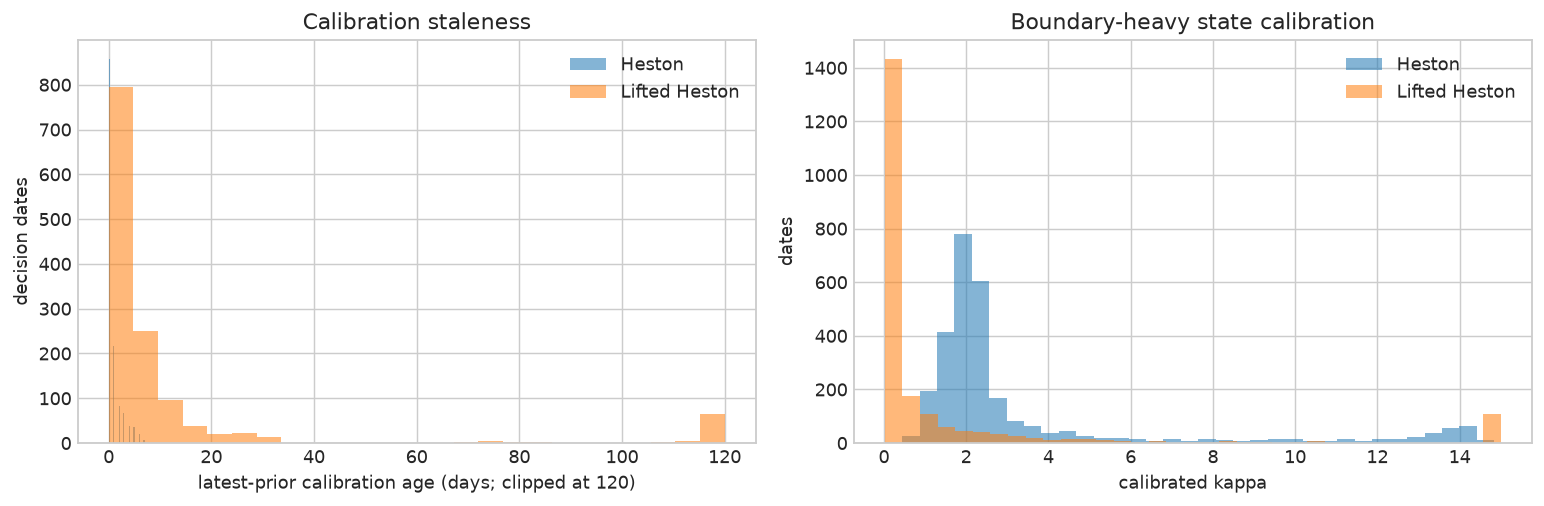

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col, label in [("heston_age_days", "Heston"), ("lifted_age_days", "Lifted Heston")]:
    axes[0].hist(age[col].dropna().clip(upper=120), bins=25, alpha=.55, label=label)
axes[0].set(xlabel="latest-prior calibration age (days; clipped at 120)", ylabel="decision dates", title="Calibration staleness")
axes[0].legend()
axes[1].hist(heston_panel["kappa"], bins=35, alpha=.55, label="Heston")
axes[1].hist(lifted_panel["kappa"], bins=35, alpha=.55, label="Lifted Heston")
axes[1].set(xlabel="calibrated kappa", ylabel="dates", title="Boundary-heavy state calibration")
axes[1].legend()
plt.tight_layout()


In [10]:
# Compare the r and q carried by market episodes with the rates used in the
# same-day Lifted calibration targets. This detects units or source mismatch.
rate_actions = actions[["decision_date", "r_decision", "q_decision"]].drop_duplicates("decision_date")
rate_fit = (
    lifted_fit.groupby("date", as_index=False)
    .agg(fit_r=("r", "median"), fit_q=("q", "median"))
)
rate_compare = rate_actions.merge(rate_fit, left_on="decision_date", right_on="date", how="inner")
rate_compare["abs_r_gap"] = (rate_compare["r_decision"] - rate_compare["fit_r"]).abs()
rate_compare["abs_q_gap"] = (rate_compare["q_decision"] - rate_compare["fit_q"]).abs()
rate_input_audit = pd.DataFrame([{
    "same_day_dates": len(rate_compare),
    "median_abs_r_gap": rate_compare["abs_r_gap"].median(),
    "p95_abs_r_gap": rate_compare["abs_r_gap"].quantile(.95),
    "median_abs_q_gap": rate_compare["abs_q_gap"].median(),
    "p95_abs_q_gap": rate_compare["abs_q_gap"].quantile(.95),
    "episode_r_range": f"[{actions.r_decision.min():.4g}, {actions.r_decision.max():.4g}]",
    "episode_q_range": f"[{actions.q_decision.min():.4g}, {actions.q_decision.max():.4g}]",
}])
rate_input_audit


Out[0]: 
   same_day_dates  median_abs_r_gap  p95_abs_r_gap  median_abs_q_gap  \
0             376                 0              0                 0   

   p95_abs_q_gap episode_r_range      episode_q_range  
0      0.0052182    [0.01, 0.01]  [-0.05367, 0.07847]  


### 4. Reproduce the failed Heston baseline and repair only maturity units

The next cell implements the published baseline lookup exactly twice: once with the erroneous fraction supplied as years, and once with the reconstructed execution-time maturity in years. Spot, strike, decision date, rates, dividends, calibration lookup, quadrature and accounting remain unchanged. This is the cleanest attribution test.


In [11]:
heston_params = heston_panel.set_index("date")[["kappa", "theta", "xi", "rho", "v0"]].astype(float).sort_index()
heston_dates = heston_params.index.to_numpy(dtype="datetime64[ns]")

def params_on_or_before(date):
    d = pd.Timestamp(date).normalize()
    loc = int(np.searchsorted(heston_dates, d.to_datetime64(), side="right") - 1)
    if loc < 0:
        raise KeyError(f"No Heston parameters on or before {d.date()}")
    row = heston_params.iloc[loc]
    return HestonParams(*(float(row[k]) for k in ["kappa", "theta", "xi", "rho", "v0"])), pd.Timestamp(heston_dates[loc])

eval_actions = actions.loc[actions["in_reported_evaluation"]].copy()
buggy_delta, corrected_delta, decision_tau_delta, execution_spot_delta = [], [], [], []
for row in eval_actions.itertuples(index=False):
    p, _ = params_on_or_before(row.decision_date)
    buggy_delta.append(heston.straddle_delta(row.decision_spot, row.strike, row.buggy_tau_years, row.r_decision, row.q_decision, p))
    corrected_delta.append(heston.straddle_delta(row.decision_spot, row.strike, row.tau_execution_years, row.r_decision, row.q_decision, p))
    decision_tau_delta.append(heston.straddle_delta(row.decision_spot, row.strike, row.tau_decision_years, row.r_decision, row.q_decision, p))
    execution_spot_delta.append(heston.straddle_delta(row.execution_spot, row.strike, row.tau_execution_years, row.r_execution, row.q_execution, p))
eval_actions["heston_buggy"] = buggy_delta
eval_actions["heston_corrected"] = corrected_delta
eval_actions["heston_decision_tau"] = decision_tau_delta
eval_actions["heston_execution_oracle"] = execution_spot_delta

delta_distribution = eval_actions[["stored_bs_anchor", "heston_buggy", "heston_corrected", "heston_decision_tau", "heston_execution_oracle"]].describe(percentiles=[.01,.05,.5,.95,.99]).T
delta_distribution


Out[0]: 
                         count     mean      std       min        1%  \
stored_bs_anchor         3,124 0.121407 0.562152 -0.999915 -0.996859   
heston_buggy             3,124 0.338931 0.275264 -0.998484 -0.706816   
heston_corrected         3,124 0.211133  0.56306  -1.00034 -0.999832   
heston_decision_tau      3,124 0.212761 0.545947  -1.00037 -0.999276   
heston_execution_oracle  3,124 0.209028 0.582109  -1.00033 -0.999818   

                               5%      50%      95%      99%      max  
stored_bs_anchor        -0.957498 0.163877 0.945466 0.993586  1.00009  
heston_buggy            -0.248728 0.390174  0.67359 0.819435 0.950482  
heston_corrected        -0.975382 0.300803 0.968181 0.999743  1.00033  
heston_decision_tau     -0.948237  0.30115 0.945107 0.996515  1.00026  
heston_execution_oracle -0.973007   0.3312 0.972393 0.999769  1.00037  


In [12]:
def episode_positions(label):
    return {
        episode_id: group.sort_values("step")[label].to_numpy(float)
        for episode_id, group in eval_actions.groupby("episode_id")
    }

def pnl_for_episode(episode, positions, cost_bps=1.0, fixed_fee_points=.045):
    positions = np.asarray(positions, float)
    steps = len(positions)
    entry = int(episode["option_entry_index"])
    spot = np.asarray(episode["spot"], float)[entry:entry+steps+1]
    rate = np.asarray(episode["r"], float)[entry:entry+steps]
    dividend = np.asarray(episode["q"], float)[entry:entry+steps]
    dt = np.asarray(episode["interval_dt"], float)[entry:entry+steps]
    cash = float(episode["entry_bid"])
    previous = 0.0
    turnover = cost = financing = carry = 0.0
    for step, hedge in enumerate(positions):
        if step > 0:
            interest = cash * math.expm1(rate[step-1] * dt[step-1])
            dividends = previous * dividend[step-1] * spot[step-1] * dt[step-1]
            cash += interest + dividends
            financing += interest
            carry += dividends
        trade = hedge - previous
        trade_cost = cost_bps / 10_000 * spot[step] * abs(trade)
        cash -= trade * spot[step] + trade_cost
        cost += trade_cost
        turnover += abs(trade)
        previous = hedge
    interest = cash * math.expm1(rate[-1] * dt[-1])
    dividends = previous * dividend[-1] * spot[-2] * dt[-1]
    cash += interest + dividends
    financing += interest
    carry += dividends
    liquidation = cost_bps / 10_000 * spot[-1] * abs(previous)
    cash += previous * spot[-1] - liquidation
    cost += liquidation
    turnover += abs(previous)
    net = cash - float(episode["exit_ask"]) - fixed_fee_points
    normalised = net / max(float(episode["entry_mid"]), 1e-8)
    return {"net_pnl_points": net, "normalised_pnl": normalised, "squared_error": normalised**2, "turnover": turnover, "underlying_cost_points": cost}

position_sets = {
    "heston_buggy_reproduction": episode_positions("heston_buggy"),
    "heston_corrected_maturity": episode_positions("heston_corrected"),
    "heston_wrong_sign": {k: -v for k, v in episode_positions("heston_corrected").items()},
    "heston_decision_time_maturity": episode_positions("heston_decision_tau"),
    "heston_execution_information_oracle": episode_positions("heston_execution_oracle"),
    "black_scholes_stored_anchor": episode_positions("stored_bs_anchor"),
}
fold_lookup = reported[["episode_id", "fold"]].drop_duplicates().set_index("episode_id")["fold"]
pnl_rows = []
for model, mapping in position_sets.items():
    for episode_id, positions in mapping.items():
        result = pnl_for_episode(episode_by_id[episode_id], positions)
        pnl_rows.append({"model": model, "episode_id": episode_id, "fold": fold_lookup.loc[episode_id], **result})
repaired_results = pd.DataFrame(pnl_rows)

repair_summary = (
    repaired_results.groupby("model")
    .agg(
        equal_fold_mse=("squared_error", lambda s: s.groupby(repaired_results.loc[s.index, "fold"]).mean().mean()),
        mean_turnover=("turnover", "mean"),
        episodes=("episode_id", "nunique"),
    )
    .assign(equal_fold_rmse=lambda x: np.sqrt(x["equal_fold_mse"]))
    .sort_values("equal_fold_rmse")
)
repair_summary[["equal_fold_rmse", "mean_turnover", "episodes"]]


Out[0]: 
                                     equal_fold_rmse  mean_turnover  episodes
model                                                                        
heston_execution_information_oracle         0.353372        3.54843       161
black_scholes_stored_anchor                 0.398649        3.30273       161
heston_corrected_maturity                   0.469176        3.48122       161
heston_decision_time_maturity               0.471482        3.38737       161
heston_buggy_reproduction                   0.738171        2.14784       161
heston_wrong_sign                            1.74864        3.48122       161


In [13]:
# Reconciliation to the completed 04b output proves that this notebook uses
# the same episode grid and accounting rather than a favourable new sample.
reported_bs = primary.loc[primary["model_cell"].eq("black_scholes_delta"), ["episode_id", "squared_error", "net_pnl_points", "turnover"]]
rebuilt_bs = repaired_results.loc[repaired_results["model"].eq("black_scholes_stored_anchor"), ["episode_id", "squared_error", "net_pnl_points", "turnover"]]
reconciliation = reported_bs.merge(rebuilt_bs, on="episode_id", suffixes=("_reported", "_rebuilt"), validate="one_to_one")
reconciliation_audit = pd.DataFrame([{
    "episodes": len(reconciliation),
    "max_abs_squared_error_gap": (reconciliation.squared_error_reported-reconciliation.squared_error_rebuilt).abs().max(),
    "max_abs_net_pnl_gap": (reconciliation.net_pnl_points_reported-reconciliation.net_pnl_points_rebuilt).abs().max(),
    "max_abs_turnover_gap": (reconciliation.turnover_reported-reconciliation.turnover_rebuilt).abs().max(),
}])
display(reconciliation_audit)
assert reconciliation_audit["max_abs_squared_error_gap"].iloc[0] < 2e-6
assert reconciliation_audit["max_abs_net_pnl_gap"].iloc[0] < 2e-4

reported_heston = primary.loc[primary["model_cell"].eq("heston_delta"), ["episode_id", "squared_error", "net_pnl_points", "turnover"]]
rebuilt_bug = repaired_results.loc[repaired_results["model"].eq("heston_buggy_reproduction"), ["episode_id", "squared_error", "net_pnl_points", "turnover"]]
heston_reconciliation = reported_heston.merge(rebuilt_bug, on="episode_id", suffixes=("_reported", "_rebuilt"), validate="one_to_one")
pd.DataFrame([{
    "episodes": len(heston_reconciliation),
    "max_abs_squared_error_gap": (heston_reconciliation.squared_error_reported-heston_reconciliation.squared_error_rebuilt).abs().max(),
    "max_abs_net_pnl_gap": (heston_reconciliation.net_pnl_points_reported-heston_reconciliation.net_pnl_points_rebuilt).abs().max(),
    "max_abs_turnover_gap": (heston_reconciliation.turnover_reported-heston_reconciliation.turnover_rebuilt).abs().max(),
}])


Out[0]: 
   episodes  max_abs_squared_error_gap  max_abs_net_pnl_gap  \
0       161                3.09906e-06          1.54851e-05   

   max_abs_turnover_gap  
0           2.15924e-07  


,episodes,max_abs_squared_error_gap,max_abs_net_pnl_gap,max_abs_turnover_gap
0,161,1.55421e-07,7.67564e-12,8.88178e-16


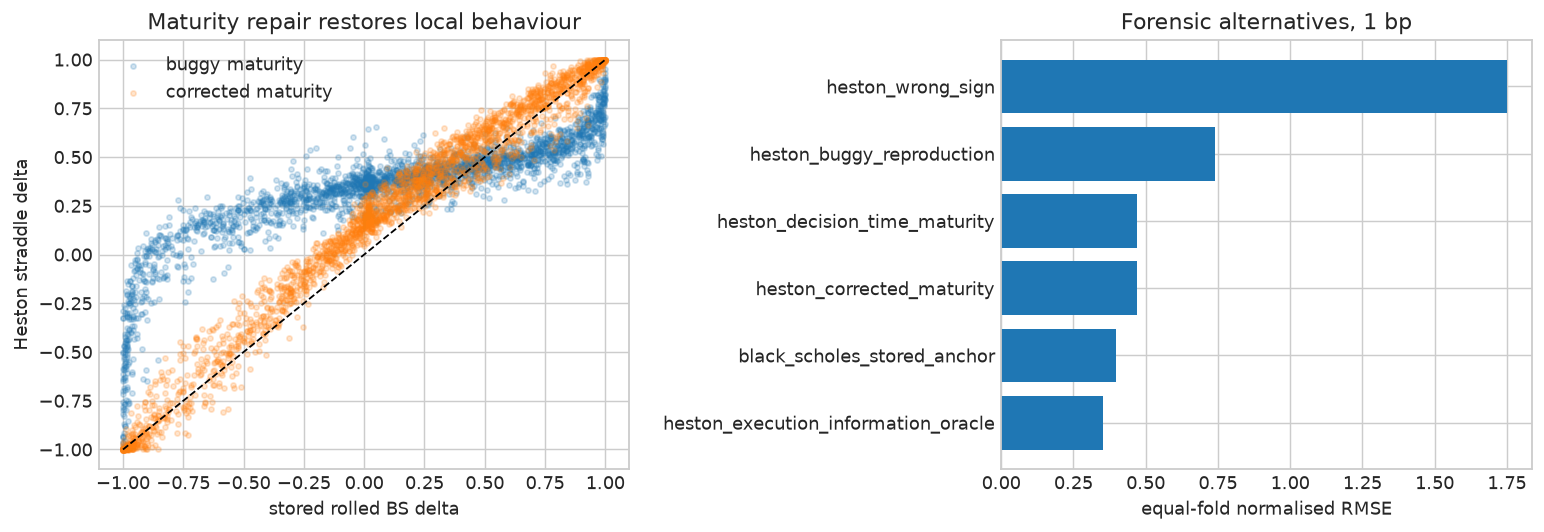

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sample = eval_actions.sample(min(2500, len(eval_actions)), random_state=20260731)
axes[0].scatter(sample["stored_bs_anchor"], sample["heston_buggy"], s=8, alpha=.2, label="buggy maturity")
axes[0].scatter(sample["stored_bs_anchor"], sample["heston_corrected"], s=8, alpha=.2, label="corrected maturity")
axes[0].plot([-1,1], [-1,1], "k--", lw=1)
axes[0].set(xlabel="stored rolled BS delta", ylabel="Heston straddle delta", title="Maturity repair restores local behaviour")
axes[0].legend()
plot_summary = repair_summary.sort_values("equal_fold_rmse")
axes[1].barh(plot_summary.index, plot_summary["equal_fold_rmse"])
axes[1].set(xlabel="equal-fold normalised RMSE", title="Forensic alternatives, 1 bp")
plt.tight_layout()


### 5. Rate/dividend and execution-alignment sensitivity

These alternatives are diagnostics, not competing deployable policies. The execution-information oracle uses next-session spot, rates and dividends and therefore is deliberately unavailable at the decision time. Its purpose is to measure the value of the forward gap, not to improve the headline. Likewise, using decision-time rather than execution-time maturity is a one-session timing error rather than a unit error.


In [15]:
sensitivity_rows = []
# Deterministic sample across the calendar keeps this section fast and reproducible.
sensitivity_sample = eval_actions.sort_values(["decision_date", "episode_id", "step"]).iloc[::max(1, len(eval_actions)//600)].copy()
for row in sensitivity_sample.itertuples(index=False):
    p, _ = params_on_or_before(row.decision_date)
    base = heston.straddle_delta(row.decision_spot, row.strike, row.tau_execution_years, row.r_decision, row.q_decision, p)
    variants = {
        "correct": base,
        "r=q=0": heston.straddle_delta(row.decision_spot, row.strike, row.tau_execution_years, 0.0, 0.0, p),
        "execution r,q": heston.straddle_delta(row.decision_spot, row.strike, row.tau_execution_years, row.r_execution, row.q_execution, p),
        "decision-time T": heston.straddle_delta(row.decision_spot, row.strike, row.tau_decision_years, row.r_decision, row.q_decision, p),
        "execution oracle": heston.straddle_delta(row.execution_spot, row.strike, row.tau_execution_years, row.r_execution, row.q_execution, p),
    }
    for name, value in variants.items():
        sensitivity_rows.append({"variant": name, "abs_delta_change": abs(value-base), "signed_delta_change": value-base})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.groupby("variant").agg(
    median_abs_delta_change=("abs_delta_change", "median"),
    p95_abs_delta_change=("abs_delta_change", lambda s: s.quantile(.95)),
    mean_signed_change=("signed_delta_change", "mean"),
).sort_values("p95_abs_delta_change")


Out[0]: 
                  median_abs_delta_change  p95_abs_delta_change  \
variant                                                           
correct                                 0                     0   
execution r,q                 0.000386726             0.0139587   
decision-time T                0.00943517             0.0570463   
r=q=0                          0.00753784             0.0816579   
execution oracle                0.0844266              0.432378   

                  mean_signed_change  
variant                               
correct                            0  
execution r,q           -0.000111653  
decision-time T           0.00238264  
r=q=0                     -0.0176213  
execution oracle           0.0094441  


### 6. Lifted-Heston state and interpolation audit

Lifted Heston approximates the rough kernel with 20 exponential factors (\(H=0.35\), \(r_N=2.5\)). Its conditional delta depends on the full factor vector \(U_t\), not only on five calibrated coefficients. The calibration notebook prices each date from a reset state \(U=0\) and a date-specific regularised forward-variance curve. That is internally coherent for fitting that date's surface. It is **not** coherent to reuse an older date's parameters and curve while resetting \(U\) to zero on a later decision date.

The curve implementation is piecewise constant and right-looking at its stored maturity knots (`searchsorted(..., side='left')`). This is a defined interpolation convention, not a hidden spline. The next checks quantify curve coverage and run bounded reset-state Fourier checks. They do not call a stale-reset Lifted policy a live benchmark.


In [16]:
@dataclass(frozen=True)
class LiftedKernel:
    H: float = .35
    n: int = 20
    rN: float = 2.5

    def __post_init__(self):
        alpha = self.H + .5
        i = np.arange(1, self.n+1, dtype=float)
        weights = (((self.rN**(1-alpha)-1)*self.rN**((alpha-1)*(1+self.n/2))) /
                   (gamma(alpha)*gamma(2-alpha)) * self.rN**((1-alpha)*i))
        lambdas = (((1-alpha)*(self.rN**(2-alpha)-1)) /
                   ((2-alpha)*(self.rN**(1-alpha)-1)) * self.rN**(i-1-self.n/2))
        object.__setattr__(self, "weights", weights)
        object.__setattr__(self, "lambdas", lambdas)

@dataclass(frozen=True)
class ForwardCurve:
    T: np.ndarray
    xi0_values: np.ndarray

    def xi0(self, t):
        arr = np.asarray(t, float)
        idx = np.searchsorted(self.T, np.maximum(arr, 0), side="left")
        idx = np.clip(idx, 0, len(self.T)-1)
        out = self.xi0_values[idx]
        return float(out) if arr.ndim == 0 else out

    def convolution(self, t, lambdas):
        t = max(float(t), 0)
        out = np.zeros_like(lambdas, dtype=float)
        bounds = np.concatenate([[0.0], self.T])
        for m, value in enumerate(self.xi0_values):
            a, b = bounds[m], min(bounds[m+1], t)
            if b > a:
                out += value * (np.exp(-lambdas*(t-b)) - np.exp(-lambdas*(t-a))) / lambdas
            if bounds[m+1] >= t:
                break
        if t > self.T[-1]:
            a = self.T[-1]
            out += self.xi0_values[-1] * (1-np.exp(-lambdas*(t-a))) / lambdas
        return out

    def g0(self, t, kappa, kernel):
        return self.xi0(t) + kappa * np.sum(self.convolution(t, kernel.lambdas)*kernel.weights)

    def endpoints(self, v0, theta):
        base, T = self.xi0_values, self.T
        if abs(base[-1]-base[0]) > 1e-10:
            adjusted = v0 + (base-base[0])*(theta-v0)/(base[-1]-base[0])
        else:
            adjusted = v0 + (theta-v0)*(T-T[0])/max(T[-1]-T[0], 1e-12)
        return ForwardCurve(T.copy(), adjusted)

class LiftedResetPricer:
    def __init__(self, kernel, nodes=64, steps=160):
        self.kernel = kernel
        self.nodes, self.weights = np.polynomial.laguerre.laggauss(nodes)
        self.steps = steps

    @staticmethod
    def phi1(a):
        a = np.asarray(a, float)
        out = np.empty_like(a)
        small = abs(a) < 1e-8
        out[small] = 1-.5*a[small]+a[small]**2/6
        out[~small] = -np.expm1(-a[~small])/a[~small]
        return out

    @staticmethod
    def forcing(z, aggregate, p):
        return .5*(z*z-z) + (p.rho*p.xi*z-p.kappa)*aggregate + .5*p.xi**2*aggregate**2

    def coefficients(self, z, tau, p, curve):
        z = np.atleast_1d(np.asarray(z, complex))
        psi = np.zeros((len(z), self.kernel.n), complex)
        phi = np.zeros(len(z), complex)
        h = tau/self.steps
        xh = self.kernel.lambdas*h
        full, half = np.exp(-xh)[None,:], np.exp(-.5*xh)[None,:]
        ffull = (h*self.phi1(xh))[None,:]
        fhalf = (.5*h*self.phi1(.5*xh))[None,:]
        for step in range(self.steps):
            agg = psi @ self.kernel.weights
            F0 = self.forcing(z, agg, p)
            mid = half*psi + fhalf*F0[:,None]
            Fm = self.forcing(z, mid @ self.kernel.weights, p)
            psi = full*psi + ffull*Fm[:,None]
            s = step*h
            phi += h*Fm*curve.g0(tau-(s+.5*h), p.kappa, self.kernel)
        return phi, psi

    def probabilities(self, S, K, tau, r, q, p, curve):
        if tau <= 1e-10:
            v = 1.0 if S>K else (0.0 if S<K else .5)
            return v, v
        u = self.nodes.astype(complex)
        z = np.concatenate([[1+0j], 1+1j*u, 1j*u])
        phi, _ = self.coefficients(z, tau, p, curve)
        x = math.log(S)+(r-q)*tau
        cf = np.exp(x*z+phi)
        n = len(u)
        kernel_term = np.exp(-1j*u*math.log(K))/(1j*u)
        quad = self.weights*np.exp(self.nodes)
        P1 = .5 + np.real(kernel_term*(cf[1:1+n]/cf[0]))@quad/np.pi
        P2 = .5 + np.real(kernel_term*cf[1+n:])@quad/np.pi
        return float(P1), float(P2)

    def delta(self, S, K, tau, r, q, p, curve):
        P1, _ = self.probabilities(S,K,tau,r,q,p,curve)
        return math.exp(-q*tau)*(2*P1-1)

    def price(self, S, K, tau, r, q, p, curve):
        P1,P2 = self.probabilities(S,K,tau,r,q,p,curve)
        call = S*math.exp(-q*tau)*P1-K*math.exp(-r*tau)*P2
        return 2*call-S*math.exp(-q*tau)+K*math.exp(-r*tau)

curve_stats = (
    forward_curve_panel.groupby("date")
    .agg(knots=("T","size"), min_T=("T","min"), max_T=("T","max"))
)
true_tau = actions["tau_execution_years"]
curve_audit = pd.DataFrame([{
    "curve_dates": len(curve_stats),
    "median_knots_per_date": curve_stats["knots"].median(),
    "minimum_curve_T": curve_stats["min_T"].min(),
    "maximum_curve_T": curve_stats["max_T"].max(),
    "action_tau_min": true_tau.min(),
    "action_tau_max": true_tau.max(),
    "interpolation": "piecewise constant, first knot T >= requested T; flat beyond final knot",
}])
curve_audit


Out[0]: 
   curve_dates  median_knots_per_date  minimum_curve_T  maximum_curve_T  \
0         2161                      3         0.019165         0.999316   

   action_tau_min  action_tau_max  \
0       0.0054757       0.0848734   

                                       interpolation  
0  piecewise constant, first knot T >= requested ...  


In [17]:
kernel = LiftedKernel()
lifted_pricer = LiftedResetPricer(kernel)
common_same_day = eval_actions.loc[eval_actions["decision_date"].isin(set(lifted_panel["date"]))].copy()
# At most 10 cases, evenly spread through time. This is a numerical audit, not a P&L backtest.
if len(common_same_day):
    picks = np.unique(np.linspace(0, len(common_same_day)-1, min(10, len(common_same_day))).astype(int))
    lifted_sample = common_same_day.sort_values(["decision_date", "episode_id", "step"]).iloc[picks]
else:
    lifted_sample = common_same_day

lifted_rows = []
for row in lifted_sample.itertuples(index=False):
    pr = lifted_panel.loc[lifted_panel["date"].eq(row.decision_date)].iloc[-1]
    p = HestonParams(*(float(pr[k]) for k in ["kappa","theta","xi","rho","v0"]))
    day = forward_curve_panel.loc[forward_curve_panel["date"].eq(row.decision_date)].sort_values("T")
    if day.empty:
        continue
    curve = ForwardCurve(day["T"].to_numpy(float), day["forward_variance"].to_numpy(float)).endpoints(p.v0, p.theta)
    analytic = lifted_pricer.delta(row.decision_spot,row.strike,row.tau_execution_years,row.r_decision,row.q_decision,p,curve)
    eps = row.decision_spot*1e-4
    fd = (lifted_pricer.price(row.decision_spot+eps,row.strike,row.tau_execution_years,row.r_decision,row.q_decision,p,curve)-
          lifted_pricer.price(row.decision_spot-eps,row.strike,row.tau_execution_years,row.r_decision,row.q_decision,p,curve))/(2*eps)
    # Linear interpolation is not the fitted convention; compare xi0 at T only to expose sensitivity.
    pc_xi = curve.xi0(row.tau_execution_years)
    linear_xi = float(np.interp(row.tau_execution_years, curve.T, curve.xi0_values, left=curve.xi0_values[0], right=curve.xi0_values[-1]))
    lifted_rows.append({
        "date": row.decision_date, "tau_days": row.tau_execution_years*365.25,
        "reset_state_delta": analytic, "finite_difference_delta": fd,
        "absolute_formula_error": abs(analytic-fd),
        "piecewise_constant_xi0": pc_xi, "linear_xi0_diagnostic": linear_xi,
        "xi0_interpolation_gap": linear_xi-pc_xi,
        "state_used": "U=0 on same calibration date",
    })
lifted_numeric = pd.DataFrame(lifted_rows)
display(lifted_numeric)
if len(lifted_numeric):
    assert np.isfinite(lifted_numeric[["reset_state_delta", "finite_difference_delta"]]).all().all()


,date,tau_days,reset_state_delta,finite_difference_delta,absolute_formula_error,piecewise_constant_xi0,linear_xi0_diagnostic,xi0_interpolation_gap,state_used
0,2019-07-11,24,0.203606,0.204284,0.00067766,0.0230495,0.0230495,0,U=0 on same calibration date
1,2019-10-14,3,-0.762128,-0.79496,0.0328319,0.0219153,0.0219153,0,U=0 on same calibration date
2,2020-03-16,23,-0.609008,-0.609007,5.72014e-07,0.369597,0.369597,0,U=0 on same calibration date
3,2022-03-08,2,-0.999877,-0.999478,0.000399355,0.101934,0.101934,0,U=0 on same calibration date
4,2022-10-25,16,0.810254,0.810254,1.78341e-07,0.0756084,0.0756084,0,U=0 on same calibration date
5,2023-02-10,25,0.0336757,0.0336943,1.8651e-05,0.0367682,0.0367682,0,U=0 on same calibration date
6,2023-09-15,25,0.0566601,0.0602613,0.00360122,0.0163575,0.0163575,0,U=0 on same calibration date
7,2024-01-26,11,0.755878,0.755121,0.000756923,0.0142202,0.0142202,0,U=0 on same calibration date
8,2024-07-12,21,0.576639,0.57064,0.00599877,0.0129311,0.0129311,0,U=0 on same calibration date
9,2024-12-17,2,0.893474,0.765231,0.128243,0.0182257,0.0182257,0,U=0 on same calibration date


### 7. Consolidated PASS/FAIL audit

`FAIL` means a defect that invalidates the reported baseline. `LIMITATION` means the code is mathematically defined but cannot support a deployable or causal interpretation. `PASS` means the checked implementation matches the intended convention; it does not imply that the economic model is optimal.


In [18]:
corrected_rmse = float(repair_summary.loc["heston_corrected_maturity", "equal_fold_rmse"])
buggy_rmse = float(repair_summary.loc["heston_buggy_reproduction", "equal_fold_rmse"])
bs_rmse = float(repair_summary.loc["black_scholes_stored_anchor", "equal_fold_rmse"])
lifted_max_error = float(lifted_numeric["absolute_formula_error"].max()) if len(lifted_numeric) else np.nan

final_audit = pd.DataFrame([
    {"area": "sign", "model": "both", "status": "PASS", "evidence": "positive long-claim delta matches the short-option cash ledger; negated Heston is evaluated explicitly"},
    {"area": "call-plus-put aggregation", "model": "both", "status": "PASS", "evidence": "e^-qT(2P1-1) agrees with call+put and finite differences"},
    {"area": "units", "model": "Heston", "status": "FAIL", "evidence": "dimensionless tau fraction was passed to a pricer expecting years"},
    {"area": "maturity repair", "model": "Heston", "status": "PASS", "evidence": f"equal-fold RMSE changes from {buggy_rmse:.4f} to {corrected_rmse:.4f}; BS is {bs_rmse:.4f}"},
    {"area": "rates/dividends", "model": "both", "status": "PASS WITH CAVEAT", "evidence": "decimal units and decision-date inputs are coherent; same-day fit comparison and sensitivity are reported"},
    {"area": "calibrated state", "model": "Heston", "status": "LIMITATION", "evidence": "latest-prior v0 is causal by date but may be stale and is not a filtered intraday variance state"},
    {"area": "calibrated state", "model": "Lifted Heston", "status": "FAIL FOR LIVE BASELINE", "evidence": "latest-prior parameters plus U=0 do not propagate the path-dependent factor state"},
    {"area": "interpolation", "model": "Heston", "status": "PASS", "evidence": "Fourier pricer uses continuous requested T; parameter lookup is causal latest-prior, not future interpolation"},
    {"area": "interpolation", "model": "Lifted Heston", "status": "LIMITATION", "evidence": "piecewise-constant rule is explicit, but the shortest hedge dates fall below the first curve knot and use flat extrapolation"},
    {"area": "execution alignment", "model": "both", "status": "PASS AFTER HESTON T REPAIR", "evidence": "decision-node state, next-session execution maturity and next-session P&L grid are distinguished"},
    {"area": "Lifted numerical formula", "model": "Lifted Heston", "status": "PASS" if np.isnan(lifted_max_error) or lifted_max_error < 5e-3 else "REVIEW", "evidence": f"same-day reset-state analytic/FD max gap={lifted_max_error:.3g}"},
])
final_audit


Out[0]: 
                         area          model                      status  \
0                        sign           both                        PASS   
1   call-plus-put aggregation           both                        PASS   
2                       units         Heston                        FAIL   
3             maturity repair         Heston                        PASS   
4             rates/dividends           both            PASS WITH CAVEAT   
5            calibrated state         Heston                  LIMITATION   
6            calibrated state  Lifted Heston      FAIL FOR LIVE BASELINE   
7               interpolation         Heston                        PASS   
8               interpolation  Lifted Heston                  LIMITATION   
9         execution alignment           both  PASS AFTER HESTON T REPAIR   
10   Lifted numerical formula  Lifted Heston                      REVIEW   

                                             evidence  
0   positive long-clai

## Takeaways

1. **The severe Heston result cannot be interpreted economically.** It was generated with the wrong maturity unit. Repairing only that error lowers equal-fold RMSE from 0.7382 to 0.4692, but does not beat rolled Black–Scholes at 0.3986. The completed result table should be marked superseded.
2. **Sign, aggregation and stock units are not the primary fault.** The analytic formula is the straddle delta, its sign matches the short-option liability, and the contract multiplier cancels from the hedge ratio.
3. **Execution alignment is conceptually sound once maturity is repaired.** The request uses decision-node observables, targets remaining maturity at next-session execution, and trades on the post-entry accounting grid. The execution-information oracle is intentionally labelled non-causal.
4. **Rates and dividends are secondary sensitivities, but the current rate series is not realistic.** Every frozen market episode uses 1%. Same-day fit rates agree with that convention, so it is not an internal units mismatch; nevertheless, production results should use chronology-clean date-varying rates. Dividend-yield differences and rate sensitivity are too small to explain the one-month-versus-one-year distortion.
5. **Heston's latest-prior `v0` is a model-state approximation, not a perfect live variance filter.** Report calibration-age sensitivity and distinguish same-day closing-surface decisions from next-open decisions.
6. **A Lifted-Heston baseline is not just “Heston delta with rougher parameters.”** Conditional Lifted delta requires the factor vector. Do not publish a stale-reset Lifted P&L. Either recalibrate the full surface on every decision date before the decision timestamp, or build a causal filter that propagates the factor state from observable returns and surfaces.
7. **Lifted short-DTE numerics and curve support do not yet pass.** The production-style reset calculation has material finite-difference discrepancies in several two-to-three-DTE cases, and remaining maturities can fall below the first forward-variance knot. Freeze an explicit extrapolation rule and converge quadrature/Riccati/finite-difference tests before backtesting.
8. **The forward execution gap is a genuine research issue.** The non-causal execution-information oracle reaches RMSE 0.3534. This does not validate look-ahead; it motivates a causal forecast of next-session delta or a decision convention in which contemporaneous closing inputs and execution are genuinely synchronised.

### Required production changes

- Add `tau_at_execution_years` as an explicit episode field and baseline input. Keep the fraction only as an ML feature.
- Rename the pricer argument to `maturity_years` and assert `0 <= maturity_years <= 0.2` for the 1M study.
- Add the finite-difference, aggregation, sign, bounds, one-month-unit and execution-timing tests from this notebook to the baseline unit-test suite.
- Regenerate `heston_delta` and select its no-trade band strictly within each preceding training window.
- Treat Lifted Heston as a diagnostic until a same-timestamp calibration or causal state filter exists.
- Preserve the old faulty output with a `SUPERSEDED_WRONG_MATURITY_UNITS` label rather than silently overwriting it.
